# User-Based Collaborative Filtering pada MovieLens (ml-latest-small)

Prediksi rating dan rekomendasi Top-N dengan user-based CF. Prediksi rating dinilai dengan MAE, MSE, RMSE, dan NMSE; rekomendasi Top-N dengan NDCG@N.

## 0. Setup & parameter

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

if not os.path.exists("ml-latest-small/ratings.csv"):
    !wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
    !unzip -q -o ml-latest-small.zip
print(os.listdir("ml-latest-small"))

['README.txt', 'tags.csv', 'links.csv', 'ratings.csv', 'movies.csv']


In [2]:
SEED          = 42
TEST_SIZE     = 0.2
K             = 30
N_LIST        = [5, 10]
REL_THRESHOLD = 4.0

BLUE, ORANGE, AQUA, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"

## 1. EDA

In [3]:
ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies  = pd.read_csv("ml-latest-small/movies.csv")
print("ratings.shape =", ratings.shape, "| movies.shape =", movies.shape)
display(ratings.head())
display(movies.head())

ratings.shape = (100836, 4) | movies.shape = (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
n_users   = ratings.userId.nunique()
n_movies  = ratings.movieId.nunique()
n_ratings = len(ratings)
sparsity  = 1 - n_ratings / (n_users * n_movies)

summary = pd.DataFrame({
    "Nilai": [n_users, n_movies, n_ratings, f"{sparsity*100:.2f}%",
              ratings.rating.min(), ratings.rating.max(), round(ratings.rating.mean(), 3)]},
    index=["Jumlah user", "Jumlah film (yang dirating)", "Jumlah rating", "Sparsity",
           "Rating min", "Rating max", "Rating rata-rata"])
display(summary)

per_user  = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()
print("\nRating per user : min %d | median %d | max %d" % (per_user.min(), per_user.median(), per_user.max()))
print("Rating per film : min %d | median %d | max %d" % (per_movie.min(), per_movie.median(), per_movie.max()))

,Nilai
Jumlah user,610
Jumlah film (yang dirating),9724
Jumlah rating,100836
Sparsity,98.30%
Rating min,0.5
Rating max,5.0
Rating rata-rata,3.502



Rating per user : min 20 | median 70 | max 2698
Rating per film : min 1 | median 3 | max 329


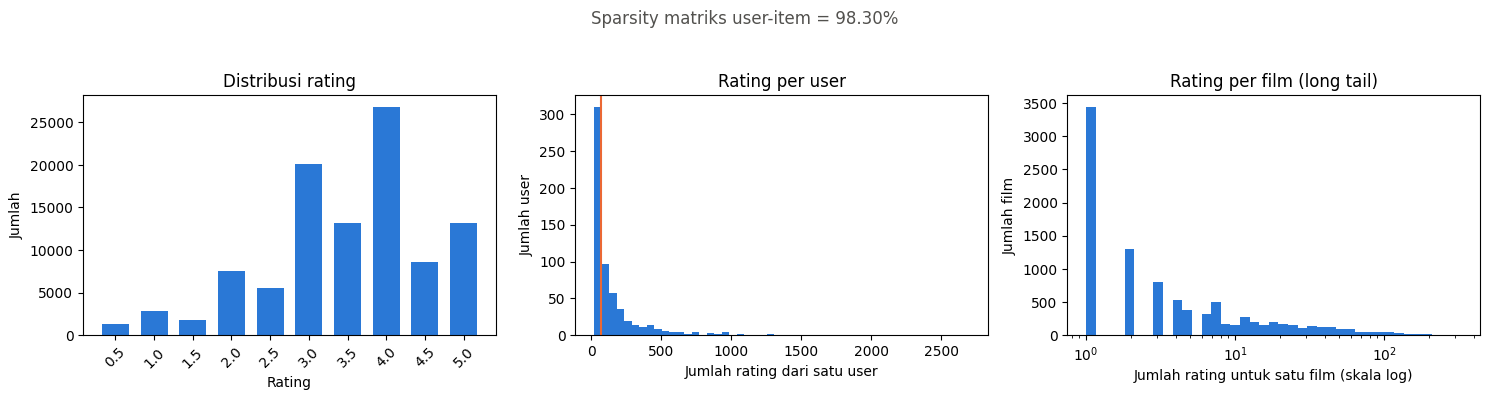

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

vc = ratings.rating.value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=BLUE, width=0.7)
ax[0].set(title="Distribusi rating", xlabel="Rating", ylabel="Jumlah")
ax[0].tick_params(axis="x", labelrotation=45)

ax[1].hist(per_user, bins=50, color=BLUE)
ax[1].axvline(per_user.median(), color=ORANGE, lw=1.5)
ax[1].set(title="Rating per user", xlabel="Jumlah rating dari satu user", ylabel="Jumlah user")

ax[2].hist(per_movie, bins=np.logspace(0, np.log10(per_movie.max()), 40), color=BLUE)
ax[2].set_xscale("log")
ax[2].set(title="Rating per film (long tail)", xlabel="Jumlah rating untuk satu film (skala log)", ylabel="Jumlah film")

fig.suptitle(f"Sparsity matriks user-item = {sparsity*100:.2f}%", y=1.04, color=INK2)
plt.tight_layout(); plt.savefig("fig_01_eda.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Preprocessing & split

Data dibagi 80/20 (seed 42). Rating di test disembunyikan dari model, lalu diprediksi dan dibandingkan dengan rating aslinya. Rata-rata user dan similarity hanya dihitung dari train.

In [6]:
print("Missing per kolom:\n", ratings.isna().sum().to_string())
dups = ratings.duplicated(subset=["userId", "movieId"]).sum()
print("\nDuplikat (userId, movieId):", dups)
ratings = ratings.drop_duplicates(subset=["userId", "movieId"]).drop(columns=["timestamp"])

uid = {u: i for i, u in enumerate(sorted(ratings.userId.unique()))}
iid = {m: i for i, m in enumerate(sorted(ratings.movieId.unique()))}
ratings["u"] = ratings.userId.map(uid)
ratings["i"] = ratings.movieId.map(iid)
N_U, N_I = len(uid), len(iid)
inv_uid = {v: k for k, v in uid.items()}
inv_iid = {v: k for k, v in iid.items()}
R_MIN, R_MAX = float(ratings.rating.min()), float(ratings.rating.max())
print(f"\nN_U={N_U}, N_I={N_I}, rating {R_MIN}-{R_MAX}, rmax-rmin={R_MAX-R_MIN}")

movie_info = movies.set_index("movieId")
def title_of(i):  return movie_info.loc[inv_iid[i], "title"]
def genres_of(i): return movie_info.loc[inv_iid[i], "genres"]

Missing per kolom:
 userId       0
movieId      0
rating       0
timestamp    0

Duplikat (userId, movieId): 0

N_U=610, N_I=9724, rating 0.5-5.0, rmax-rmin=4.5


In [7]:
def split_df(df, test_size, seed):
    perm = np.random.default_rng(seed).permutation(len(df))
    n_test = int(round(len(df) * test_size))
    return df.iloc[perm[n_test:]].reset_index(drop=True), df.iloc[perm[:n_test]].reset_index(drop=True)

train_df, test_df = split_df(ratings[["u", "i", "rating"]], TEST_SIZE, SEED)
print("train:", train_df.shape, "| test:", test_df.shape)

overlap = pd.merge(train_df[["u", "i"]], test_df[["u", "i"]], on=["u", "i"]).shape[0]
print("Pasangan (user,item) yang muncul di train DAN test:", overlap, "(harus 0)")
print("User di test tapi tidak punya rating di train:", len(set(test_df.u) - set(train_df.u)))

train: (80669, 3) | test: (20167, 3)
Pasangan (user,item) yang muncul di train DAN test: 0 (harus 0)
User di test tapi tidak punya rating di train: 0


## 3. Model User-Based CF

- **Similarity:** Pearson antar user pada item co-rated.
- **Neighbor:** maksimal k = 30 user dengan sim > 0 yang sudah merating item p.
- **Prediksi:** `pred(a,p) = r̄_a + Σ sim(a,b)·(r_bp − r̄_b) / Σ sim(a,b)`; bila tidak ada neighbor, dipakai r̄_a.
- **Top-N:** prediksi semua item yang belum dirating, lalu ambil N tertinggi.

In [8]:
class UserCF:
    def __init__(self, k=30, r_min=0.5, r_max=5.0):
        self.k, self.r_min, self.r_max = k, r_min, r_max

    def fit(self, train_df, n_users, n_items):
        u, i, r = train_df.u.values, train_df.i.values, train_df.rating.values.astype(float)
        R = np.zeros((n_users, n_items)); M = np.zeros((n_users, n_items))
        R[u, i] = r; M[u, i] = 1.0
        self.R, self.M = R, M
        cnt = M.sum(1)
        self.global_mean = r.mean()
        self.user_mean = np.where(cnt > 0, R.sum(1) / np.maximum(cnt, 1), self.global_mean)
        self.Dc = (R - self.user_mean[:, None]) * M
        self.sim = self._pearson(R, M)
        return self

    def _pearson(self, R, M):
        n   = M @ M.T
        Sx  = R @ M.T
        Sxx = (R * R) @ M.T
        Sxy = R @ R.T
        nn  = np.maximum(n, 1)
        cov = Sxy - Sx * Sx.T / nn
        va  = np.clip(Sxx - Sx ** 2 / nn, 0, None)
        den = np.sqrt(va * va.T)
        sim = np.divide(cov, den, out=np.zeros_like(cov), where=den > 1e-12)
        sim = np.clip(sim, -1, 1)
        np.fill_diagonal(sim, 0.0)
        return sim

    def _predict_user(self, u, items, k, chunk=3000):
        s = np.where(self.sim[u] > 0, self.sim[u], 0.0)
        raw = np.empty(len(items)); nneigh = np.zeros(len(items), dtype=int)
        for a in range(0, len(items), chunk):
            J = items[a:a + chunk]
            W = s[:, None] * self.M[:, J]
            kk = min(k, W.shape[0])
            idx = np.argpartition(-W, kk - 1, axis=0)[:kk]
            Wk = np.take_along_axis(W, idx, 0)
            Dk = np.take_along_axis(self.Dc[:, J], idx, 0)
            den = Wk.sum(0)
            off = np.divide((Wk * Dk).sum(0), den, out=np.zeros(len(J)), where=den > 0)
            raw[a:a + chunk] = self.user_mean[u] + off
            nneigh[a:a + chunk] = (Wk > 0).sum(0)
        return raw, nneigh

    def predict_pairs(self, users, items, k=None, clip=True):
        k = k or self.k
        users, items = np.asarray(users), np.asarray(items)
        pred = np.empty(len(users)); nn = np.zeros(len(users), dtype=int)
        for u, pos in pd.Series(np.arange(len(users))).groupby(users).indices.items():
            p, n_ = self._predict_user(u, items[pos], k)
            pred[pos], nn[pos] = p, n_
        return (np.clip(pred, self.r_min, self.r_max) if clip else pred), nn

    def recommend(self, u, N, exclude_items, k=None):
        k = k or self.k
        cand = np.setdiff1d(np.arange(self.M.shape[1]), np.asarray(list(exclude_items)))
        raw, nn = self._predict_user(u, cand, k)
        ok = nn >= 1
        cand, raw, nn = cand[ok], raw[ok], nn[ok]
        top = np.argsort(-raw, kind="stable")[:N]
        return pd.DataFrame({"i": cand[top], "pred": np.clip(raw[top], self.r_min, self.r_max),
                             "pred_unclipped": raw[top], "n_neighbors": nn[top]})

### 3.1 Contoh satu prediksi

Satu pasangan user-film dari test. Prediksi dibandingkan dengan rating aslinya.

In [9]:
model = UserCF(k=K, r_min=R_MIN, r_max=R_MAX).fit(train_df, N_U, N_I)
print("Model siap. Similarity matrix:", model.sim.shape)

def explain_prediction(model, u, i, k, true_rating=None):
    s = np.where(model.sim[u] > 0, model.sim[u], 0.0)
    w = s * model.M[:, i]
    cand = np.where(w > 0)[0]
    top = cand[np.argsort(-w[cand])[:k]]

    tbl = pd.DataFrame({
        "userId neighbor": [inv_uid[b] for b in top],
        "sim": w[top],
        "rating mereka (r_bp)": model.R[top, i],
        "rata-rata mereka (r_b)": model.user_mean[top],
        "selisih (r_bp - r_b)": model.Dc[top, i],
    })
    tbl["sim x selisih"] = tbl["sim"] * tbl["selisih (r_bp - r_b)"]

    offset = tbl["sim x selisih"].sum() / tbl["sim"].sum()
    raw = model.user_mean[u] + offset
    pred = float(np.clip(raw, R_MIN, R_MAX))

    print(f"User {inv_uid[u]} | Film: {title_of(i)}")
    print(f"Rata-rata user (r_a)          = {model.user_mean[u]:.3f}")
    print(f"Jumlah neighbor dipakai       = {len(top)}")
    print(f"Σ sim·selisih / Σ sim         = {offset:+.3f}")
    print(f"Prediksi = {model.user_mean[u]:.3f} {offset:+.3f} = {raw:.3f}  -> clip [{R_MIN}, {R_MAX}] = {pred:.3f}")
    if true_rating is not None:
        print(f"Rating asli (disembunyikan)   = {true_rating}   | selisih = {abs(pred - true_rating):.3f}")

    p_model = model.predict_pairs([u], [i], k=k)[0][0]
    assert abs(p_model - pred) < 1e-9, "hasil tidak sama dengan predict_pairs"
    display(tbl.round(3).reset_index(drop=True))

_, nn_all = model.predict_pairs(test_df.u.values, test_df.i.values, k=K)
row = test_df[nn_all >= 10].iloc[0]
explain_prediction(model, int(row.u), int(row.i), K, true_rating=row.rating)

Model siap. Similarity matrix: (610, 610)
User 226 | Film: Gladiator (2000)
Rata-rata user (r_a)          = 3.473
Jumlah neighbor dipakai       = 30
Σ sim·selisih / Σ sim         = +0.360
Prediksi = 3.473 +0.360 = 3.833  -> clip [0.5, 5.0] = 3.833
Rating asli (disembunyikan)   = 4.0   | selisih = 0.167


,userId neighbor,sim,rating mereka (r_bp),rata-rata mereka (r_b),selisih (r_bp - r_b),sim x selisih
0,333,1.000,4.0,2.636,1.364,1.364
1,299,0.920,5.0,3.636,1.364,1.255
2,209,0.866,4.0,4.188,-0.188,-0.162
3,427,0.843,4.0,3.068,0.932,0.786
4,457,0.719,5.0,3.514,1.486,1.069
5,400,0.709,4.0,4.500,-0.500,-0.355
6,326,0.638,5.0,3.968,1.032,0.658
7,249,0.595,4.0,3.681,0.319,0.190
8,287,0.584,2.5,2.623,-0.123,-0.072
9,172,0.569,4.0,3.841,0.159,0.091


## 4. Evaluasi prediksi rating

MAE = Σ|p − r| / n, MSE = Σ(p − r)² / n, RMSE = √MSE, NMSE = MSE / (rmax − rmin).

In [10]:
def rating_metrics(y, p, r_min=R_MIN, r_max=R_MAX):
    y, p = np.asarray(y, float), np.asarray(p, float)
    mae  = np.mean(np.abs(p - y))
    mse  = np.mean((p - y) ** 2)
    return {"MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "NMSE": mse / (r_max - r_min)}

p_test, nn_test = model.predict_pairs(test_df.u.values, test_df.i.values, k=K)
res = rating_metrics(test_df.rating, p_test)
display(pd.DataFrame(res, index=[f"UserCF (k={K})"]).round(4))
coverage = (nn_test > 0).mean()
print(f"Coverage: {coverage*100:.1f}% pasangan test punya >= 1 neighbor; sisanya memakai rata-rata user.")

,MAE,MSE,RMSE,NMSE
UserCF (k=30),0.6769,0.7849,0.8859,0.1744


Coverage: 95.5% pasangan test punya >= 1 neighbor; sisanya memakai rata-rata user.


## 5. Top-N & NDCG

`DCG@N = Σ rel_i / log2(i+1)`, `NDCG@N = DCG@N / IDCG@N`. NDCG dihitung pada item test tiap user (user dengan ≥ 2 item test), dengan gain linear dan biner (relevan bila rating ≥ 4).

In [11]:
def dcg(rels):
    rels = np.asarray(rels, float)
    return float(np.sum(rels / np.log2(np.arange(2, len(rels) + 2))))

def ndcg_at_n(y_true, y_score, n, gain="linear", thr=REL_THRESHOLD, rng=None):
    y_true, y_score = np.asarray(y_true, float), np.asarray(y_score, float)
    rel = y_true if gain == "linear" else (y_true >= thr).astype(float)
    tie = rng.random(len(y_score)) if rng is not None else np.zeros(len(y_score))
    order = np.lexsort((tie, -y_score))
    d, ideal = dcg(rel[order][:n]), dcg(np.sort(rel)[::-1][:n])
    return np.nan if ideal == 0 else d / ideal

In [12]:
def eval_ndcg(test_df, scores, ns=N_LIST, seed=SEED):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"u": test_df.u.values, "y": test_df.rating.values, "s": np.asarray(scores, float)})
    acc = {(n, g): [] for n in ns for g in ("linear", "binary")}
    for u, g in d.groupby("u"):
        if len(g) < 2:
            continue
        for n in ns:
            for gain in ("linear", "binary"):
                acc[(n, gain)].append(ndcg_at_n(g.y.values, g.s.values, n, gain, rng=rng))
    res = {}
    for (n, gain), v in acc.items():
        v = np.array(v, float)
        label = "linear" if gain == "linear" else "biner"
        res[f"NDCG@{n} ({label})"] = np.nanmean(v)
        res[f"n user ({label}, @{n})"] = int(np.sum(~np.isnan(v)))
    return res

raw_cf, _ = model.predict_pairs(test_df.u.values, test_df.i.values, k=K, clip=False)
ndcg_res = eval_ndcg(test_df, raw_cf)
show_cols = [c for c in ndcg_res if c.startswith("NDCG")]
display(pd.DataFrame({c: ndcg_res[c] for c in show_cols}, index=[f"UserCF (k={K})"]).round(4))

n_valid     = ndcg_res[f"n user (linear, @{N_LIST[0]})"]
n_valid_bin = ndcg_res[f"n user (biner, @{N_LIST[0]})"]
print(f"User dengan >= 2 item test (NDCG linear): {n_valid} dari {N_U} user")
print(f"User yang juga punya >= 1 item relevan (rating >= {REL_THRESHOLD}) di test (NDCG biner): {n_valid_bin} dari {N_U} user")

,NDCG@5 (linear),NDCG@5 (biner),NDCG@10 (linear),NDCG@10 (biner)
UserCF (k=30),0.8778,0.764,0.903,0.7947


User dengan >= 2 item test (NDCG linear): 603 dari 610 user
User yang juga punya >= 1 item relevan (rating >= 4.0) di test (NDCG biner): 588 dari 610 user


### 5.1 Contoh rekomendasi Top-N

Top-5 film yang belum dirating untuk satu user.

In [13]:
seen_all  = ratings.groupby("u").i.apply(set)
train_cnt = train_df.groupby("u").size()

def top_n_for_user(user_id, N=5):
    u = uid[user_id]
    rec = model.recommend(u, N=N, exclude_items=seen_all[u], k=K)
    rec["judul"] = rec.i.map(title_of); rec["genre"] = rec.i.map(genres_of)
    rec = rec.rename(columns={"pred_unclipped": "skor_mentah", "pred": "prediksi", "n_neighbors": "jml neighbor"})
    return rec[["judul", "genre", "skor_mentah", "prediksi", "jml neighbor"]].round(2).reset_index(drop=True)

cands = train_cnt[(train_cnt >= 50) & (train_cnt <= 200)].index.values
demo_u = int(np.random.default_rng(SEED).choice(cands))
demo_user_id = inv_uid[demo_u]

print(f"User {demo_user_id} | {train_cnt[demo_u]} rating di train | rata-rata = {model.user_mean[demo_u]:.2f}")
print("Film yang paling disukai (train):")
for _, r in train_df[train_df.u == demo_u].sort_values("rating", ascending=False).head(5).iterrows():
    print(f"   {r.rating:.1f}  {title_of(int(r.i))}")

print(f"\nTop-5 rekomendasi (k={K}):")
hasil = top_n_for_user(demo_user_id, N=5)
display(hasil)
hasil.to_csv("hasil_topn_contoh.csv", index=False)

User 43 | 96 rating di train | rata-rata = 4.56
Film yang paling disukai (train):
   5.0  Jungle Book, The (1994)
   5.0  Junior (1994)
   5.0  Babysitter, The (1995)
   5.0  Apollo 13 (1995)
   5.0  Miracle on 34th Street (1994)

Top-5 rekomendasi (k=30):


,judul,genre,skor_mentah,prediksi,jml neighbor
0,Holiday Inn (1942),Comedy|Musical,7.21,5.0,1
1,"Day of the Doctor, The (2013)",Adventure|Drama|Sci-Fi,7.08,5.0,1
2,Doctor Who: The Time of the Doctor (2013),Adventure|Drama,7.08,5.0,1
3,Submarine (2010),Comedy|Drama|Romance,6.59,5.0,3
4,Unfaithfully Yours (1948),Comedy,6.56,5.0,1


## 6. Ringkasan hasil

In [14]:
final = pd.DataFrame({**res, **{c: ndcg_res[c] for c in show_cols}}, index=[f"UserCF (k={K})"]).round(4)
display(final)
final.to_csv("hasil_ringkasan.csv")

print("\nPARAMETER YANG DIPAKAI")
print(f"  k = {K} | N = {N_LIST} | ambang relevansi = {REL_THRESHOLD}")
print(f"  split {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} seed {SEED} | NMSE = MSE / ({R_MAX} - {R_MIN})")
print(f"  coverage = {coverage*100:.1f}% | user valid NDCG = {n_valid} dari {N_U} (linear), {n_valid_bin} (biner)")
print("File tersimpan: hasil_ringkasan.csv, hasil_topn_contoh.csv, fig_*.png (unduh dari panel Files Colab).")

,MAE,MSE,RMSE,NMSE,NDCG@5 (linear),NDCG@5 (biner),NDCG@10 (linear),NDCG@10 (biner)
UserCF (k=30),0.6769,0.7849,0.8859,0.1744,0.8778,0.764,0.903,0.7947



PARAMETER YANG DIPAKAI
  k = 30 | N = [5, 10] | ambang relevansi = 4.0
  split 80/20 seed 42 | NMSE = MSE / (5.0 - 0.5)
  coverage = 95.5% | user valid NDCG = 603 dari 610 (linear), 588 (biner)
File tersimpan: hasil_ringkasan.csv, hasil_topn_contoh.csv, fig_*.png (unduh dari panel Files Colab).
